# 09 · GloVe and pretrained embeddings

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-nlp-course/blob/main/notebooks/09_glove_and_pretrained.ipynb)

*Practical NLP — a hands-on course in classical natural language processing · Notebook 9 of 12*

word2vec (notebook 08) *predicts* context words one window at a time. **GloVe** — *Global Vectors*
(Pennington, Socher & Manning, 2014) — starts instead from the **global word–word co-occurrence matrix** of
the whole corpus and fits word vectors whose dot products reproduce the logarithm of the co-occurrence
counts. In this notebook we build a co-occurrence matrix, see why *ratios* of co-occurrence probabilities
carry meaning, train a small GloVe model **from scratch in NumPy**, compare it with a classic count-based
method (PPMI + SVD) and with word2vec, and finally look at **pretrained embeddings**: what they are, how to
load them, and what they add over vectors trained on a small corpus.

> **Offline note.** This course runs without internet access (CI sets `NLP_OFFLINE=1`), so we do **not**
> download the official pretrained GloVe files (hundreds of MB). Every vector in this notebook is trained
> locally on the cached newsgroup posts; section 6 shows the exact code you would use to load the official
> files on your own machine.

### Learning objectives
By the end of this notebook you will be able to:
1. Build a windowed word–word co-occurrence matrix and explain count-based vs predictive embeddings.
2. Use co-occurrence probability ratios to explain the intuition behind GloVe.
3. Write down the GloVe objective and train a small GloVe model with AdaGrad.
4. Compare PPMI + SVD, GloVe and word2vec vectors on neighbours and a small word-similarity test.
5. Load pretrained vectors with `gensim`'s `KeyedVectors` and explain vocabulary coverage and domain shift.

## 0 · Setup

In [1]:
# Setup — works in Google Colab and locally.
# In Colab: installs missing packages and clones the course repo (for its cached data).
# Locally / in CI: uses the files already in data/ (NLP_OFFLINE=1 forbids any download).
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nltk>=3.9", "scikit-learn", "gensim>=4.3"], check=True)
    if not Path("practical-nlp-course").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-nlp-course.git"], check=True)
    os.chdir("practical-nlp-course/notebooks")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import nlp_course
nlp_course.setup_nltk()

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)
print("Offline mode:", nlp_course.OFFLINE)
print("Cached data:", sorted(p.name for p in (ROOT / "data").iterdir() if p.suffix in {".gz", ".json"}))

Offline mode: True
Cached data: ['20newsgroups_4cat.csv.gz', 'provenance.json', 'sms_spam.csv.gz']


In [2]:
import time, tempfile
from collections import Counter
from scipy import sparse
from sklearn.utils.extmath import randomized_svd
from gensim.models import Word2Vec, KeyedVectors

## 1 · A co-occurrence matrix by hand
Count how often two words appear within a window of each other. A toy corpus first (window = 2):

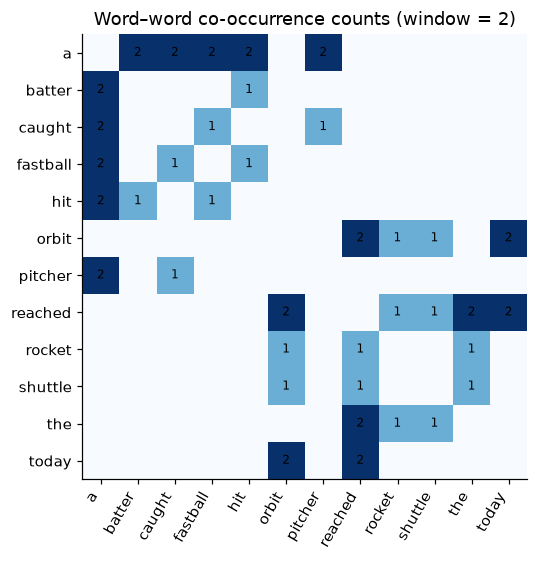

In [3]:
toy = ["the shuttle reached orbit today",
       "the rocket reached orbit today",
       "a pitcher caught a fastball",
       "a batter hit a fastball"]
toy_tok = [s.split() for s in toy]
toy_vocab = sorted({w for s in toy_tok for w in s})
ti = {w: i for i, w in enumerate(toy_vocab)}
M = np.zeros((len(toy_vocab), len(toy_vocab)), dtype=int)
for s in toy_tok:
    for i, w in enumerate(s):
        for j in range(max(0, i - 2), min(len(s), i + 3)):
            if j != i:
                M[ti[w], ti[s[j]]] += 1
toy_df = pd.DataFrame(M, index=toy_vocab, columns=toy_vocab)
fig, ax = plt.subplots(figsize=(6.2, 5.2))
ax.imshow(M, cmap="Blues")
ax.set_xticks(range(len(toy_vocab))); ax.set_xticklabels(toy_vocab, rotation=60, ha="right")
ax.set_yticks(range(len(toy_vocab))); ax.set_yticklabels(toy_vocab)
for i in range(len(toy_vocab)):
    for j in range(len(toy_vocab)):
        if M[i, j]:
            ax.text(j, i, M[i, j], ha="center", va="center", fontsize=8, color="white" if M[i, j] > 2 else "black")
ax.set_title("Word–word co-occurrence counts (window = 2)")
plt.tight_layout(); plt.savefig(DOCS / "09_cooccurrence_toy.png", bbox_inches="tight"); plt.show()

In [4]:
from sklearn.metrics.pairwise import cosine_similarity
R = cosine_similarity(M)
for a, b in [("shuttle", "rocket"), ("pitcher", "batter"), ("shuttle", "pitcher")]:
    print(f"cosine of co-occurrence rows ({a}, {b}) = {R[ti[a], ti[b]]:.3f}")

cosine of co-occurrence rows (shuttle, rocket) = 1.000
cosine of co-occurrence rows (pitcher, batter) = 0.800
cosine of co-occurrence rows (shuttle, pitcher) = 0.000


*shuttle* and *rocket* never occur together, yet their rows are identical (cosine 1.0) because they have the
same neighbours; *pitcher* and *batter* share most neighbours (0.8), and *shuttle* and *pitcher* share none (0). **Rows of a co-occurrence matrix are already word vectors** — very long and sparse ones.
Count-based methods (LSA, PPMI + SVD, GloVe) compress these rows into dense vectors; predictive methods
(word2vec) learn dense vectors directly by scanning windows. Levy & Goldberg (2014) showed the two families
are closely related: skip-gram with negative sampling implicitly factorises a shifted PMI matrix.

## 2 · The co-occurrence matrix of the newsgroups
We use all 3,729 posts, remove stopwords (with so little text, function words would dominate the counts),
keep words seen at least 10 times, and count pairs within a window of 5 words, weighting a pair at
distance $d$ by $1/d$ as GloVe does.

In [5]:
df = nlp_course.load_newsgroups()
docs = [nlp_course.preprocess(t, normalize=None) for t in df["text"]]
counts = Counter(w for d in docs for w in d)
vocab = [w for w, c in counts.most_common() if c >= 10]
w2i = {w: i for i, w in enumerate(vocab)}
V = len(vocab)

WINDOW = 5
def cooccurrence(docs, window=WINDOW):
    rows, cols, vals = [], [], []
    for d in docs:
        ids = np.array([w2i.get(w, -1) for w in d])
        for k in range(1, window + 1):
            a, b = ids[:-k], ids[k:]
            ok = (a >= 0) & (b >= 0)
            rows.append(a[ok]); cols.append(b[ok]); vals.append(np.full(ok.sum(), 1.0 / k))
    r, c, v = np.concatenate(rows), np.concatenate(cols), np.concatenate(vals)
    X = sparse.coo_matrix((np.r_[v, v], (np.r_[r, c], np.r_[c, r])), shape=(V, V)).tocsr()
    X.sum_duplicates()
    return X

X = cooccurrence(docs)
print(f"{sum(map(len, docs)):,} tokens, vocabulary V = {V:,}")
print(f"co-occurrence matrix {X.shape}, {X.nnz:,} non-zero cells ({X.nnz / V**2:.2%} of all pairs)")

381,563 tokens, vocabulary V = 5,810
co-occurrence matrix (5810, 5810), 1,452,241 non-zero cells (4.30% of all pairs)


## 3 · The GloVe intuition: ratios of co-occurrence probabilities
Let $P(k \mid i) = X_{ik} / \sum_j X_{ij}$ be the probability that word $k$ appears near word $i$. The GloVe
paper's key observation: the raw probabilities are hard to interpret, but the **ratio**
$P(k \mid i) / P(k \mid j)$ separates meaning well. Take $i$ = *shuttle* and $j$ = *pitcher*:

In [6]:
row_sums = np.asarray(X.sum(axis=1)).ravel()
def p(k, i):
    return X[w2i[i], w2i[k]] / row_sums[w2i[i]]
rows = []
for k in ["orbit", "launch", "inning", "hitter", "think", "one", "big"]:
    pi, pj = p(k, "shuttle"), p(k, "pitcher")
    rows.append({"k": k, "P(k|shuttle)": pi, "P(k|pitcher)": pj,
                 "ratio": pi / pj if pj > 0 else np.inf})
pd.DataFrame(rows).set_index("k").round({"P(k|shuttle)": 5, "P(k|pitcher)": 5, "ratio": 2})

,P(k|shuttle),P(k|pitcher),ratio
k,,,
orbit,0.00995,0.00000,inf
launch,0.02036,0.00000,inf
inning,0.00000,0.00780,0.00
hitter,0.00000,0.00270,0.00
think,0.00198,0.00222,0.89
one,0.00646,0.00858,0.75
big,0.00124,0.00090,1.37


Space words (*orbit, launch*) give a ratio far above 1 — some never occur near *pitcher*, hence an infinite
ratio — baseball words (*inning, hitter*) a ratio of 0 (they never occur near *shuttle*), and generic words
related to both or neither (*think, one, big*) a ratio close to 1 (between 0.75 and 1.37). GloVe chooses a model in which **differences of word vectors encode
these log-ratios**, which leads to the requirement

$$\mathbf{w}_i^\top \tilde{\mathbf{w}}_k + b_i + \tilde b_k \approx \log X_{ik}.$$

## 4 · Training GloVe from scratch
GloVe minimises a **weighted least-squares** loss over the non-zero cells of $X$:

$$J = \sum_{i,k:\,X_{ik}>0} f(X_{ik})\,\big(\mathbf{w}_i^\top \tilde{\mathbf{w}}_k + b_i + \tilde b_k - \log X_{ik}\big)^2,
\qquad f(x) = \min\big(1, (x/x_{\max})^{3/4}\big)$$

- $\mathbf{w}_i$ (word) and $\tilde{\mathbf{w}}_k$ (context) are two sets of vectors; the final embedding is their sum.
- $f$ down-weights rare, noisy pairs and caps very frequent pairs. The paper uses $x_{\max}=100$; our corpus
  is tiny, so we use $x_{\max}=10$.
- Only the non-zero cells are used, so training cost scales with the number of observed pairs, not $V^2$.

The official implementation uses per-pair stochastic AdaGrad updates in C. To stay fast in pure NumPy we use
**full-batch AdaGrad**: one gradient over all non-zero cells per iteration, computed with sparse
matrix products.

In [7]:
def train_glove(X, dim=50, x_max=10.0, lr=0.5, iters=150, seed=0):
    C = X.tocoo()
    I, K, x = C.row, C.col, C.data
    f, logx = np.minimum(1.0, (x / x_max) ** 0.75), np.log(x)
    rng = np.random.default_rng(seed)
    W, Wc = (rng.random((V, dim)) - 0.5) / dim, (rng.random((V, dim)) - 0.5) / dim
    b, bc = np.zeros(V), np.zeros(V)
    G = [np.full_like(W, 1e-8), np.full_like(Wc, 1e-8), np.full(V, 1e-8), np.full(V, 1e-8)]
    history = []
    for it in range(iters):
        diff = (W[I] * Wc[K]).sum(axis=1) + b[I] + bc[K] - logx
        history.append(0.5 * (f * diff ** 2).sum() / len(x))
        S = sparse.csr_matrix((f * diff, (I, K)), shape=(V, V))     # weighted errors as a sparse matrix
        grads = [S @ Wc, S.T @ W, np.asarray(S.sum(axis=1)).ravel(), np.asarray(S.sum(axis=0)).ravel()]
        for param, g, acc in zip([W, Wc, b, bc], grads, G):
            acc += g ** 2                                             # AdaGrad: per-parameter step sizes
            param -= lr * g / np.sqrt(acc)
    return W + Wc, history

t0 = time.time()
E_glove, history = train_glove(X)
print(f"trained GloVe (V={V:,}, 50 dims, 150 full-batch AdaGrad iterations) in {time.time() - t0:.0f} s")
print(f"weighted loss per cell: start {history[0]:.4f} -> end {history[-1]:.4f}")

trained GloVe (V=5,810, 50 dims, 150 full-batch AdaGrad iterations) in 80 s
weighted loss per cell: start 0.0765 -> end 0.0172


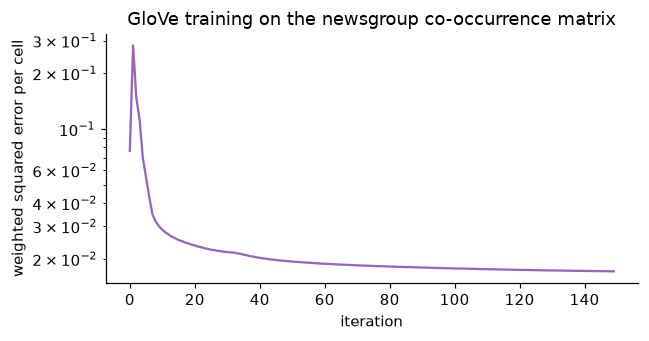

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(history, color="tab:purple")
ax.set_yscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("weighted squared error per cell")
ax.set_title("GloVe training on the newsgroup co-occurrence matrix")
plt.tight_layout(); plt.savefig(DOCS / "09_glove_loss.png", bbox_inches="tight"); plt.show()

## 5 · Comparing three embeddings
For comparison we build two more 50-dimensional embeddings over the **same vocabulary**:
- **PPMI + SVD** — the classic count-based recipe: positive pointwise mutual information
  $\text{PPMI}(i,k) = \max\big(0, \log \frac{P(i,k)}{P(i)P(k)}\big)$, then a truncated SVD;
- **word2vec (CBOW)** — trained on the same stopword-free token stream as in notebook 08's set-up.

In [9]:
def ppmi(X):
    total = X.sum()
    pi = np.asarray(X.sum(axis=1)).ravel() / total
    C = X.tocoo()
    pmi = np.log((C.data / total) / (pi[C.row] * pi[C.col]))
    keep = pmi > 0
    return sparse.csr_matrix((pmi[keep], (C.row[keep], C.col[keep])), shape=X.shape)

U, s, _ = randomized_svd(ppmi(X), n_components=50, random_state=0)
E_ppmi = U * np.sqrt(s)

t0 = time.time()
w2v = Word2Vec(docs, vector_size=50, window=WINDOW, min_count=10, sg=0, epochs=20, workers=1, seed=0)
E_w2v = np.array([w2v.wv[w] for w in vocab])
print(f"word2vec trained in {time.time() - t0:.0f} s; every vocabulary word has a vector: {all(w in w2v.wv for w in vocab)}")

def unit(E):
    return E / np.linalg.norm(E, axis=1, keepdims=True)
models = {"PPMI + SVD": unit(E_ppmi), "GloVe": unit(E_glove), "word2vec (CBOW)": unit(E_w2v)}

def nn(E, word, n=6):
    s = E @ E[w2i[word]]
    return ", ".join(vocab[i] for i in np.argsort(-s)[1:n + 1])
probe = ["orbit", "shuttle", "pitcher", "jpeg", "president", "tax"]
pd.DataFrame({name: [nn(E, w) for w in probe] for name, E in models.items()}, index=probe)

word2vec trained in 6 s; every vocabulary word has a vector: True


,PPMI + SVD,GloVe,word2vec (CBOW)
orbit,"orbital, orbits, solar, earth, spacecraft, kg","earth, planet, lunar, craft, moon, low","burn, hst, pluto, luna, lift, servicing"
shuttle,"hst, spacelab, flight, module, payload, crew","mission, space, launch, missions, main, orbit","reboost, boost, hst, centaur, launch, tug"
pitcher,"pitchers, pitches, mound, batters, pitch, bullpen","pitches, wayne, snow, random, second, jump","pitchers, batters, hitter, mound, hitters, pitches"
jpeg,"gif, jfif, jpg, tiff, ppm, converting","convert, gif, format, view, files, viewing","jfif, lossless, gif, converted, naplps, cshow"
president,"myers, mr, stephanopoulos, ms, talked, christopher","mr, stephanopoulos, said, george, going, morning","conversations, yeltsin, secretary, stephanopoulos, ambassador, congressional"
tax,"taxes, income, raise, revenue, paid, spending","income, pay, vat, federal, taxes, fired","income, taxes, raise, vat, spending, deficit"


All three methods give mostly topical neighbours from the same ~380k content tokens. PPMI + SVD and
word2vec look the cleanest (*pitcher → pitchers, mound, batters, bullpen*; *jpeg → gif, jfif, tiff*). Our
GloVe is noisier, especially for less frequent words (*pitcher → pitches, wayne, snow, random*): with
full-batch AdaGrad and only 150 iterations it is not fully converged (the loss curve is still going down),
and the official implementation also trains much longer on far more data. Neighbour lists are anecdotes,
though; let us measure.

### A small word-similarity test
Real benchmarks (WordSim-353, SimLex-999, MEN) compare model similarities with human judgements. Our corpus
is too small and specialised for them, so we build a mini test from the four topics: 40 **related** pairs
(two words from the same topic) and 40 **unrelated** pairs (words from different topics). A good embedding
gives related pairs higher cosine similarity; we report the mean of each and the fraction of
(related, unrelated) combinations ranked correctly (an AUC).

In [10]:
topics = {
    "space": ["orbit", "shuttle", "launch", "nasa", "moon", "mars", "satellite", "rocket", "lunar", "spacecraft"],
    "baseball": ["pitcher", "hitter", "inning", "season", "game", "team", "catcher", "baseball", "homer", "bat"],
    "graphics": ["image", "jpeg", "gif", "file", "format", "software", "color", "pixel", "display", "graphics"],
    "politics": ["president", "government", "tax", "congress", "clinton", "law", "senate", "federal", "income", "vote"],
}
assert all(w in w2i for ws in topics.values() for w in ws)
rng = np.random.default_rng(0)
names = list(topics)
related, unrelated = [], []
while len(related) < 40:
    t = names[rng.integers(4)]
    a, b = rng.choice(topics[t], 2, replace=False)
    if (a, b) not in related:
        related.append((a, b))
while len(unrelated) < 40:
    t1, t2 = rng.choice(names, 2, replace=False)
    pair = (rng.choice(topics[t1]), rng.choice(topics[t2]))
    if pair not in unrelated:
        unrelated.append(pair)

def score(E):
    rel = np.array([E[w2i[a]] @ E[w2i[b]] for a, b in related])
    unr = np.array([E[w2i[a]] @ E[w2i[b]] for a, b in unrelated])
    auc = (rel[:, None] > unr[None, :]).mean()
    return rel, unr, auc

results = {name: score(E) for name, E in models.items()}
pd.DataFrame({name: {"mean cos related": r.mean(), "mean cos unrelated": u.mean(), "AUC": auc}
              for name, (r, u, auc) in results.items()}).T.round(3)

,mean cos related,mean cos unrelated,AUC
PPMI + SVD,0.452,0.016,0.991
GloVe,0.252,-0.022,0.876
word2vec (CBOW),0.460,-0.015,0.965


All three embeddings separate same-topic from cross-topic pairs well above chance (AUC 0.5). On this
test PPMI + SVD scores highest (AUC 0.991), then word2vec (0.965), then our small GloVe (0.876). That
ranking is specific to a small corpus and a topical test: on large corpora and human-judged benchmarks the
three methods are much closer, and well-tuned GloVe and word2vec usually beat plain PPMI + SVD.

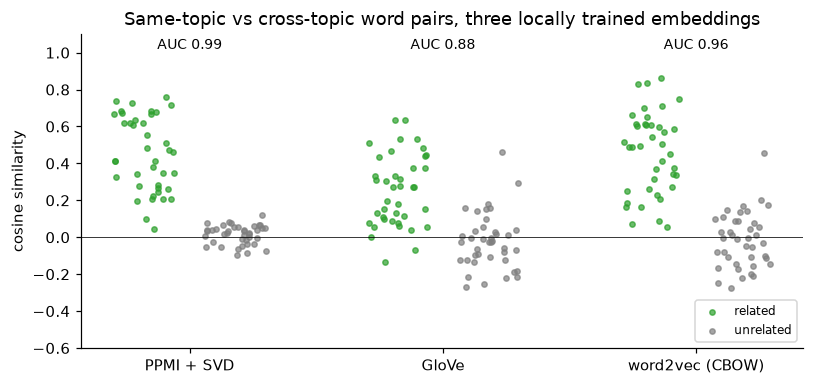

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for k, (name, (r, u, auc)) in enumerate(results.items()):
    jitter = np.random.default_rng(k).uniform(-0.12, 0.12, size=40)
    ax.scatter(k - 0.18 + jitter, r, s=12, color="tab:green", alpha=0.7, label="related" if k == 0 else None)
    ax.scatter(k + 0.18 + jitter, u, s=12, color="tab:gray", alpha=0.7, label="unrelated" if k == 0 else None)
    ax.text(k, 1.02, f"AUC {auc:.2f}", ha="center", fontsize=9)
ax.set_xticks(range(len(results))); ax.set_xticklabels(results)
ax.set_ylabel("cosine similarity"); ax.set_ylim(-0.6, 1.1)
ax.axhline(0, color="black", lw=0.5)
ax.set_title("Same-topic vs cross-topic word pairs, three locally trained embeddings")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(DOCS / "09_embedding_comparison.png", bbox_inches="tight"); plt.show()

## 6 · Pretrained embeddings
Everything above was trained on about 380k content tokens in seconds to a minute or two. **Pretrained embeddings** are the
same algorithms run once, by someone else, on enormous corpora, and published as files:

| Vectors | Trained on | Vocabulary | Dimensions |
|---|---|---|---|
| GloVe 6B | Wikipedia 2014 + Gigaword 5 (6 billion tokens) | 400k | 50, 100, 200, 300 |
| GloVe 840B | Common Crawl (840 billion tokens) | 2.2M | 300 |
| GloVe Twitter | 2 billion tweets (27 billion tokens) | 1.2M | 25, 50, 100, 200 |
| word2vec GoogleNews | Google News (about 100 billion tokens) | 3M | 300 |
| fastText | Wikipedia / Common Crawl, with sub-word units | 1–2M | 300 |

What they add over our local vectors:
- **Coverage** — hundreds of thousands of words instead of a few thousand.
- **Quality** — billions of contexts per common word make similarities and analogies far more reliable
  (*king − man + woman ≈ queen* really works with them).
- **Transfer** — a small labelled dataset can use knowledge learned from general text.

What to watch: they encode the **domain** they were trained on (Wikipedia/news, not chemistry papers or SMS
slang), they inherit **biases** present in that text, and like all static embeddings they give one vector per
word regardless of context.

### How you would load them (not executed here — needs internet)
```python
# Option 1: gensim's downloader (about 130 MB for the 100-d GloVe)
import gensim.downloader as api
glove = api.load("glove-wiki-gigaword-100")          # a KeyedVectors object

# Option 2: the official file from https://nlp.stanford.edu/projects/glove/
from gensim.models import KeyedVectors
glove = KeyedVectors.load_word2vec_format("glove.6B.100d.txt", binary=False, no_header=True)

glove.most_similar("orbit")
glove.most_similar(positive=["king", "woman"], negative=["man"])
```

### The same workflow, offline, with our own vectors
GloVe files are plain text: one word per line followed by its numbers, no header. Let us save our locally
trained GloVe vectors in exactly that format and load them back with the very same call as above — every
`KeyedVectors` method then works on them.

In [12]:
tmp = Path(tempfile.mkdtemp())
path = tmp / "newsgroups_glove.50d.txt"
with open(path, "w") as fh:
    for w, vec in zip(vocab, E_glove):
        fh.write(w + " " + " ".join(f"{v:.5f}" for v in vec) + "\n")
print(f"wrote {path.name}: {path.stat().st_size / 1e6:.1f} MB, first line starts with:")
print("   ", path.read_text().split("\n")[0][:70], "...")

kv = KeyedVectors.load_word2vec_format(str(path), binary=False, no_header=True)
print(f"\nloaded {len(kv):,} vectors of dimension {kv.vector_size}")
print("kv.most_similar('mars'):", [w for w, _ in kv.most_similar("mars", topn=5)])
print("kv.doesnt_match(['inning', 'pitcher', 'homer', 'orbit']):", kv.doesnt_match(["inning", "pitcher", "homer", "orbit"]))

wrote newsgroups_glove.50d.txt: 2.5 MB, first line starts with:
    would 0.13326 1.44296 0.24254 -1.51155 -0.16440 0.14122 -0.39366 0.425 ...

loaded 5,810 vectors of dimension 50
kv.most_similar('mars'): ['observer', 'face', 'moon', 'venus', 'planet']
kv.doesnt_match(['inning', 'pitcher', 'homer', 'orbit']): homer


The loaded vectors behave exactly like any pretrained `KeyedVectors`. Their quality, though, is that of
our small model: *mars* gets sensible neighbours (*moon, venus, planet*, and *observer* from the Mars
Observer probe), but `doesnt_match` picks *homer* instead of *orbit* — a mistake large pretrained vectors
would not make.

### Coverage and domain shift
A vocabulary learned from newsgroup posts about four topics will miss most words of a different domain.
How many tokens of the **SMS Spam Collection** have a vector in our newsgroup GloVe?

In [13]:
sms = nlp_course.load_sms()
sms_tok = [nlp_course.preprocess(t, normalize=None) for t in sms["text"]]
all_sms = [w for d in sms_tok for w in d]
covered = np.mean([w in kv.key_to_index for w in all_sms])
types = set(all_sms)
type_cov = np.mean([w in kv.key_to_index for w in types])
no_vec = np.mean([not any(w in kv.key_to_index for w in d) for d in sms_tok])
print(f"SMS tokens with a vector:        {covered:.1%}")
print(f"distinct SMS words with a vector: {type_cov:.1%} of {len(types):,}")
print(f"messages with no known word at all: {no_vec:.1%}")
missing = Counter(w for w in all_sms if w not in kv.key_to_index).most_common(15)
print("most frequent missing words:", [w for w, _ in missing])

SMS tokens with a vector:        67.3%
distinct SMS words with a vector: 33.5% of 7,570
messages with no known word at all: 2.2%
most frequent missing words: ['ur', 'gt', 'lt', 'txt', 'lor', 'pls', 'msg', 'wat', 'wan', 'amp', 'lol', 'nokia', 'urgent', 'gud', 'cant']


Two thirds of SMS tokens (67.3%) have a vector, but only a third of the distinct words (33.5%): the
frequent words are covered, the long tail is not. The most frequent missing words are SMS shorthand (*ur,
txt, lor, pls, wat, gud*), HTML entities left in the text (*gt, lt, amp*) and ordinary words that were rare
in four 1990s newsgroups (*urgent, nokia*). A large vocabulary trained on web or Twitter text would cover
many of them; for shorthand or specialised jargon you can also train on in-domain data, or use sub-word
models such as fastText that build vectors for unseen words from character n-grams.

## Exercises
**Exercise 1.** Rebuild the co-occurrence matrix with `window=2` and `window=10`, compute PPMI + SVD
(50 dims) for each, and compare the neighbours of `"shuttle"` and `"president"` and the AUC of the
word-similarity test.

In [14]:
# your code here

<details>
<summary><b>Show solution</b></summary>

window=10 gives a higher AUC (0.999) than window=2 (0.977): wider windows capture topical relatedness, which is exactly what our same-topic test rewards. The neighbour lists change less than for word2vec because PPMI already ignores how often very frequent pairs occur.

```python
for win in [2, 10]:
    Xw = cooccurrence(docs, window=win)
    U, s, _ = randomized_svd(ppmi(Xw), n_components=50, random_state=0)
    E = unit(U * np.sqrt(s))
    print(f"window={win:>2}  AUC={score(E)[2]:.3f}")
    for w in ["shuttle", "president"]:
        print(f"    {w:>9}: {nn(E, w)}")
```
</details>

In [15]:
for win in [2, 10]:
    Xw = cooccurrence(docs, window=win)
    U, s, _ = randomized_svd(ppmi(Xw), n_components=50, random_state=0)
    E = unit(U * np.sqrt(s))
    print(f"window={win:>2}  AUC={score(E)[2]:.3f}")
    for w in ["shuttle", "president"]:
        print(f"    {w:>9}: {nn(E, w)}")

window= 2  AUC=0.977
      shuttle: flight, payload, spacelab, hst, hubble, sts
    president: myers, mr, stephanopoulos, ms, conversations, talked


window=10  AUC=0.999
      shuttle: crew, payload, vehicle, module, flight, hst
    president: mr, myers, stephanopoulos, ms, senator, miyazawa


**Exercise 2.** The GloVe embedding is the sum $W + \tilde W$. Modify `train_glove` to return `W` and
`Wc` separately, and compare the AUC of `W` alone, `Wc` alone and their sum (use `iters=100` to save time).

In [16]:
# your code here

<details>
<summary><b>Show solution</b></summary>

With 100 iterations: W alone 0.827, W~ alone 0.748, the sum 0.864. Because X is symmetric, W and W~ learn equivalent information from different random starts; summing them averages out some noise, which is why the GloVe paper uses the sum.

```python
import inspect
src = inspect.getsource(train_glove).replace("return W + Wc, history", "return W, Wc")
src = src.replace("def train_glove(", "def train_glove_parts(")
exec(src)
W_, Wc_ = train_glove_parts(X, iters=100)
for name, E in [("W", W_), ("W~", Wc_), ("W + W~", W_ + Wc_)]:
    print(f"{name:>7}: AUC = {score(unit(E))[2]:.3f}")
```
</details>

In [17]:
import inspect
src = inspect.getsource(train_glove).replace("return W + Wc, history", "return W, Wc")
src = src.replace("def train_glove(", "def train_glove_parts(")
exec(src)
W_, Wc_ = train_glove_parts(X, iters=100)
for name, E in [("W", W_), ("W~", Wc_), ("W + W~", W_ + Wc_)]:
    print(f"{name:>7}: AUC = {score(unit(E))[2]:.3f}")

      W: AUC = 0.827
     W~: AUC = 0.748
 W + W~: AUC = 0.864


**Exercise 3.** Use the loaded `kv` vectors to build **document vectors** for the newsgroup posts by
averaging the vectors of their known words, and compute test precision@10 (same-topic training posts among
the 10 nearest by cosine), as in notebook 06.

In [18]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Averaged GloVe vectors reach precision@10 = 0.709 — below TF-IDF (0.744 in notebook 06) and averaged word2vec (0.816 in notebook 08), consistent with our GloVe being the weakest of the three embeddings here. As in notebook 08, the vectors saw all posts' text (not labels) during training, so this is slightly optimistic.

```python
def doc_vec(tokens):
    vecs = [kv[w] for w in tokens if w in kv.key_to_index]
    return np.mean(vecs, axis=0) if vecs else np.zeros(kv.vector_size)
D = np.array([doc_vec(d) for d in docs])
is_train = (df["subset"] == "train").to_numpy()
y = df["category"].to_numpy()
ok = np.abs(D).sum(axis=1) > 0
Dtr, ytr, Dte, yte = D[is_train], y[is_train], D[~is_train & ok], y[~is_train & ok]
top = np.argsort(-cosine_similarity(Dte, Dtr), axis=1)[:, :10]
print(f"averaged GloVe vectors: precision@10 = {(ytr[top] == yte[:, None]).mean():.3f}")
```
</details>

In [19]:
def doc_vec(tokens):
    vecs = [kv[w] for w in tokens if w in kv.key_to_index]
    return np.mean(vecs, axis=0) if vecs else np.zeros(kv.vector_size)
D = np.array([doc_vec(d) for d in docs])
is_train = (df["subset"] == "train").to_numpy()
y = df["category"].to_numpy()
ok = np.abs(D).sum(axis=1) > 0
Dtr, ytr, Dte, yte = D[is_train], y[is_train], D[~is_train & ok], y[~is_train & ok]
top = np.argsort(-cosine_similarity(Dte, Dtr), axis=1)[:, :10]
print(f"averaged GloVe vectors: precision@10 = {(ytr[top] == yte[:, None]).mean():.3f}")

averaged GloVe vectors: precision@10 = 0.709


## Summary
- Rows of a word–word co-occurrence matrix are (sparse) word vectors; count-based methods compress them.
- GloVe fits $\mathbf{w}_i^\top\tilde{\mathbf{w}}_k + b_i + \tilde b_k \approx \log X_{ik}$ with a weighted least-squares loss, motivated by co-occurrence probability ratios.
- We trained GloVe from scratch in NumPy and compared it with PPMI + SVD and word2vec on the same vocabulary; on this small corpus PPMI + SVD (AUC 0.991) and word2vec (0.965) beat our under-trained GloVe (0.876).
- Pretrained embeddings (GloVe, word2vec, fastText) bring huge vocabularies and better similarities, but carry their training domain and biases; `KeyedVectors` loads them all.
- Vectors trained on one domain cover another domain poorly: our newsgroup vocabulary misses many SMS words.

**Next:** 10 · Text classification with classic ML *(coming in the next batch)*.